# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Abdul Qudoosz
- **Student ID:** 023-24-0233
- **Section:** G
- **GitHub:** https://github.com/abdulqudoos181005
- **Kaggle:** https://www.kaggle.com/abdulqudoos7860 
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
import warnings; warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 100

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
# YOUR CODE HERE
df = pd.read_csv('Mall_Customers.csv')   # upload the CSV next to the notebook (Colab: left panel > Files)
df = df.rename(columns={'Genre': 'Gender',                  # some copies of the file use 'Genre'
                        'Annual Income (k$)': 'Income',
                        'Spending Score (1-100)': 'Spending'})
print('Shape            :', df.shape)
print('Missing values   :', int(df.isna().sum().sum()))
print('Duplicate rows   :', int(df.duplicated().sum()))
print('Gender counts    :\n', df['Gender'].value_counts())
df[['Age', 'Income', 'Spending']].describe().round(2)

Shape            : (200, 5)
Missing values   : 0
Duplicate rows   : 0
Gender counts    :
 Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


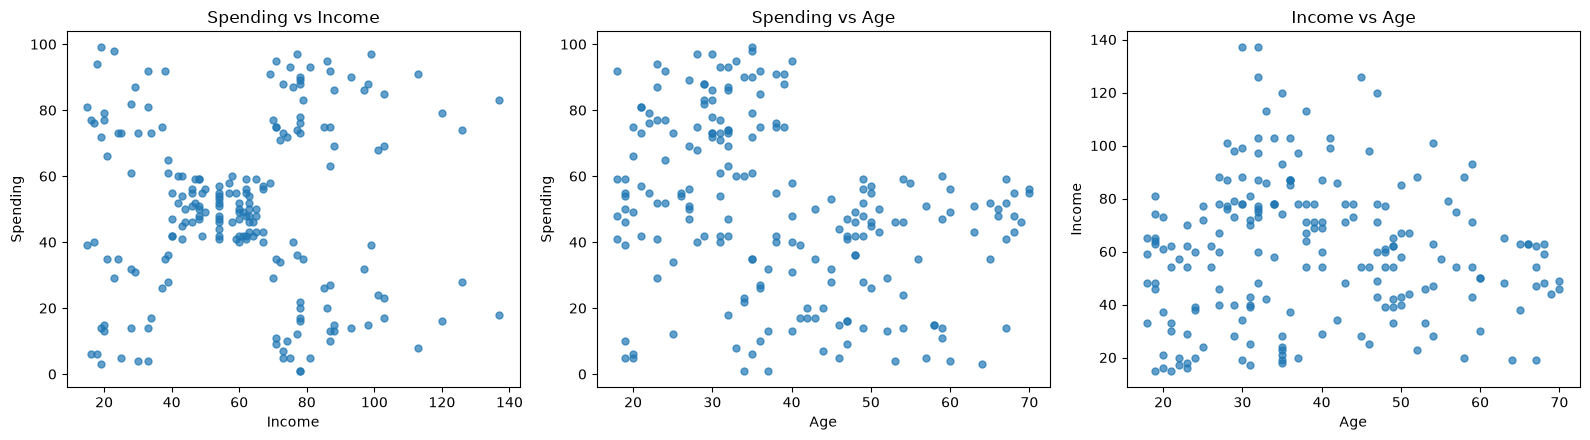

In [3]:
# YOUR CODE HERE
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
pairs = [('Income', 'Spending'), ('Age', 'Spending'), ('Age', 'Income')]   # (x, y)
for a, (xc, yc) in zip(ax, pairs):
    a.scatter(df[xc], df[yc], s=25, alpha=0.7)
    a.set_xlabel(xc); a.set_ylabel(yc); a.set_title(f'{yc} vs {xc}')
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

**(a)** *Spending vs Income:* **5 groups**, clearly separated (low income/low spending, low income/high spending, a big centre group, high income/low spending, high income/high spending). *Spending vs Age:* only a loose pattern (correlation = -0.33): customers aged 40+ (84 people) have a mean Spending of only 36.8, while customers under 40 spread from 1 to 99, so at most about 2 vague, overlapping groups. *Income vs Age:* **one cloud, no groups** (correlation = -0.01). **Spending vs Income** shows the groups most clearly.

**(b)** Accuracy needs a correct answer (a target column) to compare against, and a train/test split exists to test predictions of that target on unseen rows. Mall Customers has no target: nobody knows the 'right' group of customer 1, so there is nothing to score. A clustering is judged by how tight and separated the groups are (inertia, silhouette), by plots and by whether the groups make business sense.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])                                  # starting centroids
it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])                 # shape (9, 2)
    lab = dist.argmin(axis=1)                              # assign step
    new_m = np.array([x[lab == k].mean() for k in range(2)])   # update step
    print(f'Iteration {it}: C1 = {x[lab==0].astype(int).tolist()}   C2 = {x[lab==1].astype(int).tolist()}   '
          f'-> new centroids = {new_m}')
    if np.allclose(new_m, m):                              # convergence
        break
    m = new_m
inertia1 = ((x - m[lab]) ** 2).sum()
print('\nFinal centroids:', m, '| Inertia:', inertia1)
print('Matches lecture (7, 25, 150)?', np.allclose(m, [7, 25]) and np.isclose(inertia1, 150))

Iteration 1: C1 = [2, 4, 3]   C2 = [10, 12, 20, 30, 11, 25]   -> new centroids = [ 3. 18.]
Iteration 2: C1 = [2, 4, 10, 3]   C2 = [12, 20, 30, 11, 25]   -> new centroids = [ 4.75 19.6 ]
Iteration 3: C1 = [2, 4, 10, 12, 3, 11]   C2 = [20, 30, 25]   -> new centroids = [ 7. 25.]
Iteration 4: C1 = [2, 4, 10, 12, 3, 11]   C2 = [20, 30, 25]   -> new centroids = [ 7. 25.]

Final centroids: [ 7. 25.] | Inertia: 150.0
Matches lecture (7, 25, 150)? True


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
# YOUR CODE HERE
P = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)
M = P[[0, 1]].copy()                                       # start with P1 and P2
it = 0
while True:
    it += 1
    D = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))   # (6, 2) Euclidean
    lab = D.argmin(axis=1)
    new_M = np.array([P[lab == k].mean(axis=0) for k in range(2)])
    print(f'Iteration {it}: clusters = {["C"+str(l+1) for l in lab]}')
    print(f'            centroids M1 = {M[0].round(2)}, M2 = {M[1].round(2)}')
    if it == 1:
        print('            distance table (iteration 1):')
        print(pd.DataFrame(D.round(2), index=[f'P{i+1}' for i in range(6)], columns=['d(M1)', 'd(M2)']).to_string())
    if np.allclose(new_M, M):
        break
    M = new_M
print('\nFinal distance table:')
print(pd.DataFrame(D.round(2), index=[f'P{i+1}' for i in range(6)], columns=['d(M1)', 'd(M2)']).to_string())
print('\nFinal centroids:', M.round(2).tolist(), '| iterations:', it)
# hand check of d(P3, M2) in iteration 1: P3 = (168, 60), M2 = P2 = (170, 56)
print('Hand check d(P3,M2) =', round(np.sqrt((168 - 170) ** 2 + (60 - 56) ** 2), 2))

Iteration 1: clusters = ['C1', 'C2', 'C2', 'C1', 'C1', 'C1']
            centroids M1 = [185.  72.], M2 = [170.  56.]
            distance table (iteration 1):
    d(M1)  d(M2)
P1   0.00  21.93
P2  21.93   0.00
P3  20.81   4.47
P4   7.21  15.00
P5   3.00  20.00
P6   5.83  27.66
Iteration 2: clusters = ['C1', 'C2', 'C2', 'C1', 'C1', 'C1']
            centroids M1 = [183.5   72.25], M2 = [169.  58.]

Final distance table:
    d(M1)  d(M2)
P1   1.52  21.26
P2  21.13   2.24
P3  19.76   2.24
P4   6.19  14.14
P5   1.52  19.10
P6   6.54  26.87

Final centroids: [[183.5, 72.25], [169.0, 58.0]] | iterations: 2
Hand check d(P3,M2) = 4.47


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [8]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):
    """K-Means from scratch. Returns labels, centroids, inertia, n_iterations."""
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    C = np.asarray(init_centroids, dtype=float).reshape(len(init_centroids), -1).copy()
    for it in range(1, max_iter + 1):
        D = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))   # distances (n, K)
        labels = D.argmin(axis=1)                                         # assign
        new_C = C.copy()                                                  # empty cluster keeps old centroid
        for k in range(len(C)):
            if (labels == k).any():
                new_C[k] = X[labels == k].mean(axis=0)                    # update
        if np.allclose(new_C, C):                                         # converged
            break
        C = new_C
    inertia = ((X - C[labels]) ** 2).sum()
    return labels, C, inertia, it

In [9]:
# YOUR CODE HERE
lab, C, inert, n_it = my_kmeans(x, [4, 11])
print('Example 1 -> centroids:', C.ravel(), '| inertia:', inert, '| iterations:', n_it)

Example 1 -> centroids: [ 7. 25.] | inertia: 150.0 | iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [10]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values.astype(float)       # 200 x 2
init5 = X2[:5].copy()
lab_me, C_me, in_me, it_me = my_kmeans(X2, init5)
km = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm='lloyd').fit(X2)
print(f'Iterations : mine = {it_me}, sklearn = {km.n_iter_}')
print(f'Inertia    : mine = {in_me:.4f}, sklearn = {km.inertia_:.4f}')
print('Labels identical    :', np.array_equal(lab_me, km.labels_))
print('Centroids identical :', np.allclose(C_me, km.cluster_centers_))
print('Max centroid difference:', np.abs(C_me - km.cluster_centers_).max())

Iterations : mine = 4, sklearn = 4
Inertia    : mine = 44448.4554, sklearn = 44448.4554
Labels identical    : True
Centroids identical : True
Max centroid difference: 2.842170943040401e-14


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


In [ ]:
# YOUR CODE HERE


### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [ ]:
# YOUR CODE HERE


In [ ]:
# YOUR CODE HERE


### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [ ]:
# YOUR CODE HERE


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


In [ ]:
# YOUR CODE HERE


### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


In [ ]:
# YOUR CODE HERE


**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


In [ ]:
# YOUR CODE HERE


### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [ ]:
# YOUR CODE HERE


In [ ]:
# YOUR CODE HERE


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


In [ ]:
# YOUR CODE HERE


**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [ ]:
# YOUR CODE HERE


In [ ]:
# YOUR CODE HERE


### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [ ]:
# YOUR CODE HERE


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [ ]:
# YOUR CODE HERE


In [ ]:
# YOUR CODE HERE


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [ ]:
# YOUR CODE HERE


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [ ]:
# YOUR CODE HERE


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a)

(b)

(c)

(d)


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [ ]:
# YOUR CODE HERE


**Executive Summary** (6-8 lines)

*Your summary here.*


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a)

(b)

(c)

(d)


---